In [1]:
from matplotlib import pyplot as plt

import numpy as np
from astropy.coordinates import SkyCoord

import subprocess
import logging
import os

from astropy.io import fits
from shutil import move

In [2]:
# ======================================================================
# A utility function
# ======================================================================
def runCmd( str_cmd, p_shell=True ):
    """ 
    A wrapper to run system commands.
      
    Parameters
    ----------
    str_cmd: str      
      Command string to be executed in the shell
    
    p_shell: bool
      If True (default), command will be executed through the shell, and all 
      cout/cerr messages will be available.
      If False, exception is the only way to find out problems during the call.

    Returns
    -------
      0 if some error, or 1 if all was OK

    Notes
    -----
    TODO:
      - allow to launch commands in background 
      - best checking of error when shell=True
    """
           
    logging.info("runCmd: Running command: {0}".format(str_cmd))
    
    try:
        p = subprocess.Popen(str_cmd, bufsize = 0, shell = p_shell, stdin = subprocess.PIPE, 
                             stdout = subprocess.PIPE, stderr = subprocess.PIPE, 
                             close_fds = True)
    except Exception as e:
        logging.info("Some error while running command...")
        print(e)
        raise
    
    
    #Warning
    #We use communicate() rather than .stdin.write, .stdout.read or .stderr.read 
    #to avoid deadlocks due to any of the other OS pipe buffers filling up and 
    #blocking the child process.(Python Ref.doc)

    (stdoutdata, stderrdata) = p.communicate()
    err = stdoutdata.decode('ascii') + " " + stderrdata.decode('ascii')

    # IMPORTANT: Next checking (only available when shell=True) not always detect all kind of errors !!
    if err.count('WARNING: Significant inaccuracy'):
        logging.info(("Canno't get accuracy astrometric calibration"))
        return 2
    elif (err.count('ERROR ') or err.count('error ') or err.count("Error ")\
      or err.count('*Error*')\
      or err.count('Segmentation fault') or err.count("command not found") \
      or err.count('No source found') \
      or err.count("No such file or directory")
      or err.count('WARNING: Not enough matched detections') # SCAMP
      or err.count('WARNING: Significant inaccuracy likely to occur in projection')): #SCAMP
        logging.info("An error happened while running command --> {0}".format(err))
        logging.info(stderrdata.decode('ascii'))
        return 1 # ERROR
    else:
        logging.info(stdoutdata.decode('ascii'))
        return 0 # NO ERROR

In [3]:
def write_sex_default_outpars(output_dir):
    """Minimal procedure to write a sextractor output
    pars file needed to subsequently run scamp."""
    lines = """NUMBER                   Running object number                                    
ALPHA_J2000
DELTA_J2000
FWHM_IMAGE               FWHM assuming a gaussian core                             [pixel]                                         
ELLIPTICITY              1 - B_IMAGE/A_IMAGE                                      
"""
    open(output_dir+'/sex_default.param', 'w').close()
    with open(output_dir+'/sex_default.param', 'a') as f:
        for aline in lines.split('\n'):
            print(aline, file=f)

In [4]:
def write_sex_default_nnw(output_dir):
    """Procedure to write basic sextractor .nnw file"""
    lines = """NNW
# Neural Network Weights for the SExtractor star/galaxy classifier (V1.3)
# inputs:	9 for profile parameters + 1 for seeing.
# outputs:	``Stellarity index'' (0.0 to 1.0)
# Seeing FWHM range: from 0.025 to 5.5'' (images must have 1.5 < FWHM < 5 pixels)
# Optimized for Moffat profiles with 2<= beta <= 4.

 3 10 10  1

-1.56604e+00 -2.48265e+00 -1.44564e+00 -1.24675e+00 -9.44913e-01 -5.22453e-01  4.61342e-02  8.31957e-01  2.15505e+00  2.64769e-01
 3.03477e+00  2.69561e+00  3.16188e+00  3.34497e+00  3.51885e+00  3.65570e+00  3.74856e+00  3.84541e+00  4.22811e+00  3.27734e+00

-3.22480e-01 -2.12804e+00  6.50750e-01 -1.11242e+00 -1.40683e+00 -1.55944e+00 -1.84558e+00 -1.18946e-01  5.52395e-01 -4.36564e-01 -5.30052e+00
 4.62594e-01 -3.29127e+00  1.10950e+00 -6.01857e-01  1.29492e-01  1.42290e+00  2.90741e+00  2.44058e+00 -9.19118e-01  8.42851e-01 -4.69824e+00
-2.57424e+00  8.96469e-01  8.34775e-01  2.18845e+00  2.46526e+00  8.60878e-02 -6.88080e-01 -1.33623e-02  9.30403e-02  1.64942e+00 -1.01231e+00
 4.81041e+00  1.53747e+00 -1.12216e+00 -3.16008e+00 -1.67404e+00 -1.75767e+00 -1.29310e+00  5.59549e-01  8.08468e-01 -1.01592e-02 -7.54052e+00
 1.01933e+01 -2.09484e+01 -1.07426e+00  9.87912e-01  6.05210e-01 -6.04535e-02 -5.87826e-01 -7.94117e-01 -4.89190e-01 -8.12710e-02 -2.07067e+01
-5.31793e+00  7.94240e+00 -4.64165e+00 -4.37436e+00 -1.55417e+00  7.54368e-01  1.09608e+00  1.45967e+00  1.62946e+00 -1.01301e+00  1.13514e-01
 2.20336e-01  1.70056e+00 -5.20105e-01 -4.28330e-01  1.57258e-03 -3.36502e-01 -8.18568e-02 -7.16163e+00  8.23195e+00 -1.71561e-02 -1.13749e+01
 3.75075e+00  7.25399e+00 -1.75325e+00 -2.68814e+00 -3.71128e+00 -4.62933e+00 -2.13747e+00 -1.89186e-01  1.29122e+00 -7.49380e-01  6.71712e-01
-8.41923e-01  4.64997e+00  5.65808e-01 -3.08277e-01 -1.01687e+00  1.73127e-01 -8.92130e-01  1.89044e+00 -2.75543e-01 -7.72828e-01  5.36745e-01
-3.65598e+00  7.56997e+00 -3.76373e+00 -1.74542e+00 -1.37540e-01 -5.55400e-01 -1.59195e-01  1.27910e-01  1.91906e+00  1.42119e+00 -4.35502e+00

-1.70059e+00 -3.65695e+00  1.22367e+00 -5.74367e-01 -3.29571e+00  2.46316e+00  5.22353e+00  2.42038e+00  1.22919e+00 -9.22250e-01 -2.32028e+00


 0.00000e+00 
 1.00000e+00"""
    open(output_dir+'/default.nnw', 'w').close()
    with open(output_dir+'/default.nnw', 'a') as f:
        for aline in lines.split('\n'):
            print(aline, file=f)

In [5]:
def write_sex_default_conv(output_dir):
    """Procedure to write basic sextractor .conv file."""
    lines = """CONV NORM
# 3x3 ``all-ground'' convolution mask with FWHM = 2 pixels.
1 2 1
2 4 2
1 2 1"""
    open(output_dir+'/default.conv', 'w').close()
    with open(output_dir+'/default.conv', 'a') as f:
        for aline in lines.split('\n'):
            print(aline, file=f)

In [6]:
def write_sex_default(output_dir, output_cat):
    """Procedure to write default.sex file, minimally."""
    lines = """# Default configuration file for SExtractor 2.19.5
# EB 2014-03-19
#
 
#-------------------------------- Catalog ------------------------------------
""" + "CATALOG_NAME    "+output_cat+ " # name of the output catalog" + """
CATALOG_TYPE     ASCII_HEAD     # NONE,ASCII,ASCII_HEAD, ASCII_SKYCAT,
                                # ASCII_VOTABLE, FITS_1.0 or FITS_LDAC
PARAMETERS_NAME  sex_default.param  # name of the file containing catalog contents
 
#------------------------------- Extraction ----------------------------------
 
DETECT_TYPE      CCD            # CCD (linear) or PHOTO (with gamma correction)
DETECT_MINAREA   8              # min. # of pixels above threshold
DETECT_THRESH    3.0            # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
ANALYSIS_THRESH  3.0            # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
 
FILTER           Y              # apply filter for detection (Y or N)?
FILTER_NAME      default.conv   # name of the file containing the filter
 
DEBLEND_NTHRESH  32             # Number of deblending sub-thresholds
DEBLEND_MINCONT  0.005          # Minimum contrast parameter for deblending
 
CLEAN            Y              # Clean spurious detections? (Y or N)?
CLEAN_PARAM      1.0            # Cleaning efficiency
 
MASK_TYPE        CORRECT        # type of detection MASKing: can be one of
                                # NONE, BLANK or CORRECT
 
#------------------------------ Photometry -----------------------------------
 
PHOT_APERTURES   5              # MAG_APER aperture diameter(s) in pixels
PHOT_AUTOPARAMS  2.5, 3.5       # MAG_AUTO parameters: <Kron_fact>,<min_radius>
PHOT_PETROPARAMS 2.0, 3.5       # MAG_PETRO parameters: <Petrosian_fact>,
                                # <min_radius>
 
SATUR_LEVEL      50000.0        # level (in ADUs) at which arises saturation
SATUR_KEY        SATURATE       # keyword for saturation level (in ADUs)
 
MAG_ZEROPOINT    25.0            # magnitude zero-point
MAG_GAMMA        4.0            # gamma of emulsion (for photographic scans)
GAIN             2.6            # detector gain in e-/ADU
GAIN_KEY         GAIN           # keyword for detector gain in e-/ADU
PIXEL_SCALE      0            # size of pixel in arcsec (0=use FITS WCS info)
 
#------------------------- Star/Galaxy Separation ----------------------------
 
SEEING_FWHM      1.2            # stellar FWHM in arcsec
STARNNW_NAME     default.nnw    # Neural-Network_Weight table filename
 
#------------------------------ Background -----------------------------------
 
BACK_SIZE        64             # Background mesh: <size> or <width>,<height>
BACK_FILTERSIZE  3              # Background filter: <size> or <width>,<height>
 
BACKPHOTO_TYPE   GLOBAL         # can be GLOBAL or LOCAL
 
#------------------------------ Check Image ----------------------------------
 
CHECKIMAGE_TYPE  APERTURES      # can be NONE, BACKGROUND, BACKGROUND_RMS,
                                # MINIBACKGROUND, MINIBACK_RMS, -BACKGROUND,
                                # FILTERED, OBJECTS, -OBJECTS, SEGMENTATION,
                                # or APERTURES
CHECKIMAGE_NAME  check_"""+output_cat+""".fits     # Filename for the check-image
 
#--------------------- Memory (change with caution!) -------------------------
 
MEMORY_OBJSTACK  3000           # number of objects in stack
MEMORY_PIXSTACK  300000         # number of pixels in stack
MEMORY_BUFSIZE   1024           # number of lines in buffer
 
#----------------------------- Miscellaneous ---------------------------------
 
VERBOSE_TYPE     NORMAL         # can be QUIET, NORMAL or FULL
HEADER_SUFFIX    .head          # Filename extension for additional headers
WRITE_XML        N              # Write XML file (Y/N)?
XML_NAME         sex.xml        # Filename for XML output
"""
    open(output_dir+'/default.sex', 'w').close()
    with open(output_dir+'/default.sex', 'a') as f:
        for aline in lines.split('\n'):
            print(aline, file=f)


In [7]:
def get_fwhm_e(target_dir, filt):
    #target_dir : Swarp_dir with the calibrated images
    #filt: filter of the image, NB_659 or r_SDSS
    
    os.chdir(target_dir)
    
    #write the files needed to run sextractor
    write_sex_default_outpars(target_dir)
    write_sex_default_nnw(target_dir)
    write_sex_default_conv(target_dir)
    write_sex_default(target_dir, 'output_sex_{0}.dat'.format(filt))
    
    #determine the name of the image
    image_name = target_dir[:-10].split('/')[-1]
    image_name = image_name.split('_')
    if len(image_name) == 4:
        image_name = image_name[0]+'_'+image_name[1]
    else:
        image_name = image_name[0]
    image_name = image_name+'_{0}_cal.fits'.format(filt)
    
    #run sextractor
    sex_run_str = 'sex {0} -c default.sex'.format(image_name)
    runCmd(sex_run_str)

In [19]:
def update_header(median_fwhm, median_e, fits_name):

    #we define an aux name
    aux_name = fits_name[:-5] + '_aux.fits'
    
    #we open the image and get the header
    hdul = fits.open(fits_name)
    hdr = hdul[0].header
    
    #we add the headers of the fwhm and e
    hdr['FWHM'] = (median_fwhm, 'Median of FWHM of stars [arcsec]')
    hdr['ELLIPTI'] = (median_e, 'Median of ellipticities of stars')
    
    #update the header
    hdul.writeto(aux_name)
    #move(aux_name, fits_name)
    hdul.close()

In [17]:
def matching(target_dir, filt, target_name):

    #path to the file names
    aux_name = target_dir+'/output_match.dat'
    tsv_name = target_dir+'/mefpp_zp_skymapper_phot_{0}.tsv'.format(filt)
    sex_name = target_dir+'/output_sex_{0}.dat'.format(filt)
    
    #load the data and create the skycoords
    ttsv = np.loadtxt(tsv_name,dtype='str', usecols=(1,2))
    ra_tsv = ttsv[1:,0].astype('float')
    dec_tsv = ttsv[1:,1].astype('float')
    print(f"{len(ra_tsv)} tsv results retrieved")
       
    tsex = np.loadtxt(sex_name)
    ra_sex = tsex[:,1]
    dec_sex = tsex[:,2]
    fwhm_sex = tsex[:,3]
    e_sex = tsex[:,4]
    print(f"{len(ra_sex)} sex results retrieved")
    
    cat_tsv = SkyCoord(ra=ra_tsv, dec=dec_tsv, unit='deg')
    cat_sex = SkyCoord(ra=ra_sex, dec=dec_sex, unit='deg')
    
    #do the match
    idx, d2d, d3d = cat_tsv.match_to_catalog_sky(cat_sex)  
    print(f"total number of match: {len(d2d)}")

    #we selected the fwhm and e from the match
    matches_fwhm = fwhm_sex[idx]
    matches_e = e_sex[idx]    
    
    #1pixel = 0.021 arcsec, according to OMEGACAM instrumentation page
    matches_fwhm *= 0.021
    
    #we open the file and add the fwhm and e
    new = open(aux_name,'w')

    c = -1
    with open(tsv_name,'r') as f:
        for line in f:
            if c == -1:
                new.write('{} {} {}\n'.format(line[:-2], 'FWHM [arcsec]', 'Ellipticyty [1-A/B]'))
            else:    
                new.write('{} {} {}\n'.format(line[:-2], matches_fwhm[c], matches_e[c]))
            c += 1
    new.close()
    
    #we update the tsv file 
    move(aux_name, tsv_name)
    
    #we update the header
    median_fwhm = np.median(matches_fwhm)
    median_e = np.median(matches_e)
    fits_name = target_dir+'/{0}_{1}_cal.fits'.format(target_name, filt)
    update_header(median_fwhm, median_e, fits_name)
    
    #we do the plots
    nbin = int(np.log(len(d2d))/np.log(2))
    fig, axs = plt.subplots(1,2, figsize=(10,6))
    axs[0].hist(matches_fwhm, bins=nbin)
    axs[1].hist(matches_e, bins=nbin)

    axs[0].set_title('FWHM')
    axs[1].set_title('Ellipticity')
    axs[0].set_ylabel('Counts')
    axs[0].set_xlabel('FWHM [arcsec]')
    axs[1].set_xlabel('Ellipticity [1 - B/A]')

    plt.savefig('fwhm_e_hist_{0}.png'.format(filt))
    plt.show()
    

13151 tsv results retrieved
60541 sex results retrieved
total number of match: 13151


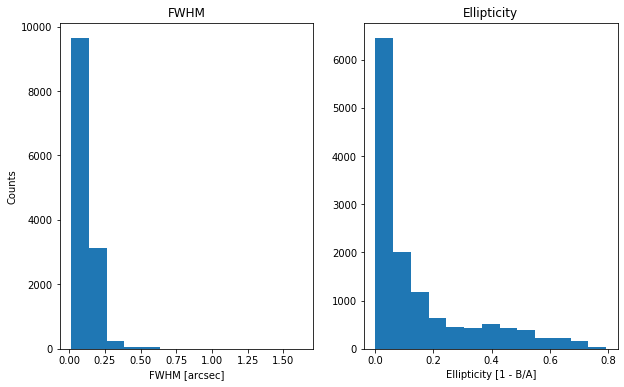

13154 tsv results retrieved
62716 sex results retrieved
total number of match: 13154


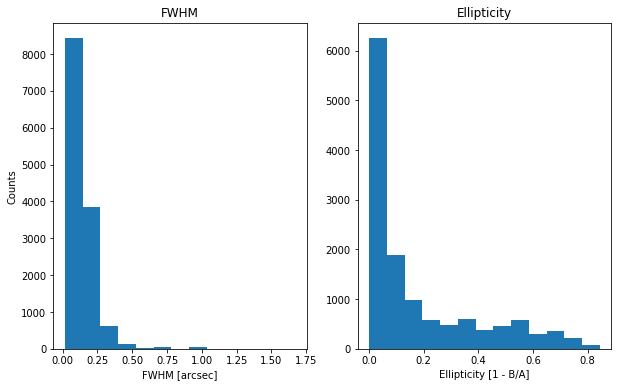

In [20]:
base_dir='/home/lceledon/local_storage/omegacam/testing/reduced/science/science/'
target_dir='BD_Pav_184311p900_m573044p9'

#get the target name
aux = target_dir.split('_')
if len(aux) == 4:
    target_name = aux[0]+'_'+aux[1]
else:
    target_name = aux[0]

#run sextractor for both filters
get_fwhm_e(base_dir+target_dir+'/Swarp_dir','NB_659')
get_fwhm_e(base_dir+target_dir+'/Swarp_dir','r_SDSS')

#do the match
matching(base_dir+target_dir+'/Swarp_dir','NB_659', target_name)
matching(base_dir+target_dir+'/Swarp_dir','r_SDSS', target_name)

#do the plot